# Omni Assistant — экспериментальное исследование ASR → VLM → TTS

**OTUS LLM Engineering · 8 ноября 2026 · отчёт на русском**

## Краткие выводы

- Реализован голосовой мультимодальный пайплайн: локальный **Whisper base** → облачный **Qwen3.6-35B** (Yandex AI Studio) → локальный **Silero TTS**; веб-интерфейс — Gradio.
- На умеренно зашумлённом аудио (SNR 15 dB) ASR допустила ошибки, но VLM смогла восстановить намерение; при SNR 5 dB запрос фактически потерял смысл.
- В обоих тестах чтения этикетки Qwen правильно определила **12,4 г белка на 100 г**.
- На фотографии растения модель **не придумала отсутствующие автомобили**.
- Наблюдались высокие задержки Whisper (8–11 с) и отдельные ASR-галлюцинации. Измерения единичные, не бенчмарк производительности.

> **Важно:** в исходном задании предусмотрена локальная 4-битная Qwen3-VL-4B. Здесь использована доступная облачная Qwen3.6-35B как функциональная замена. Это отклонение от требований, которое необходимо обозначить при сдаче.


## 1. Методика и ограничения

**Сценарии:** обычный вопрос о содержимом холодильника; аудио с SNR 15 dB и 5 dB; этикетка на полном изображении и её увеличенный фрагмент; заведомо некорректный вопрос об автомобилях на фотографии растения.

**Измеряемые величины:** ASR, VLM, TTS и TOTAL latency в секундах; транскрипция и ответ. Время и текст фиксируются скриптом `evaluate.py` в `experiments/results/*/result.json`. Локальный `noise_test.py` пишет `experiments/results/asr_noise/report.json`.

**Ограничения:** одиночные прогоны; различия между конфигурациями не являются причинным доказательством; оценки визуальной точности делаются по известным эталонам; *WER нельзя достоверно рассчитать без вручную проверенной эталонной транскрипции*. У Qwen нет прямого доступа к исходному аудио — только к тексту Whisper и изображению. Параметры Whisper между `noise_test.py` и `pipeline.py` могут отличаться.


## 2. Загрузка фактических результатов

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

# Запускай Notebook из корня репозитория omni-assistant или из notebooks/.
CANDIDATES = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in CANDIDATES if (p / "experiments/results").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Не найдена experiments/results. Запусти Notebook из корня проекта или notebooks/.")
RESULT_DIR = ROOT / "experiments/results"
print("Корень проекта:", ROOT)


Корень проекта: /home/ruslan/Documents/OTUS-LLM-Engeneering/23/omni-assistant


## Демонстрация: входные файлы → промежуточный текст → голосовой ответ

Следующие ячейки используют **уже сохранённые данные финального запуска**. Они не обращаются к облачному API. Это обязательная цепочка демонстрации из задания OTUS: показать входное изображение и аудиовопрос, транскрипцию, текст модели и полученный WAV. Для повторной живой обработки есть **необязательная** ячейка ниже.

1. Входное изображение:


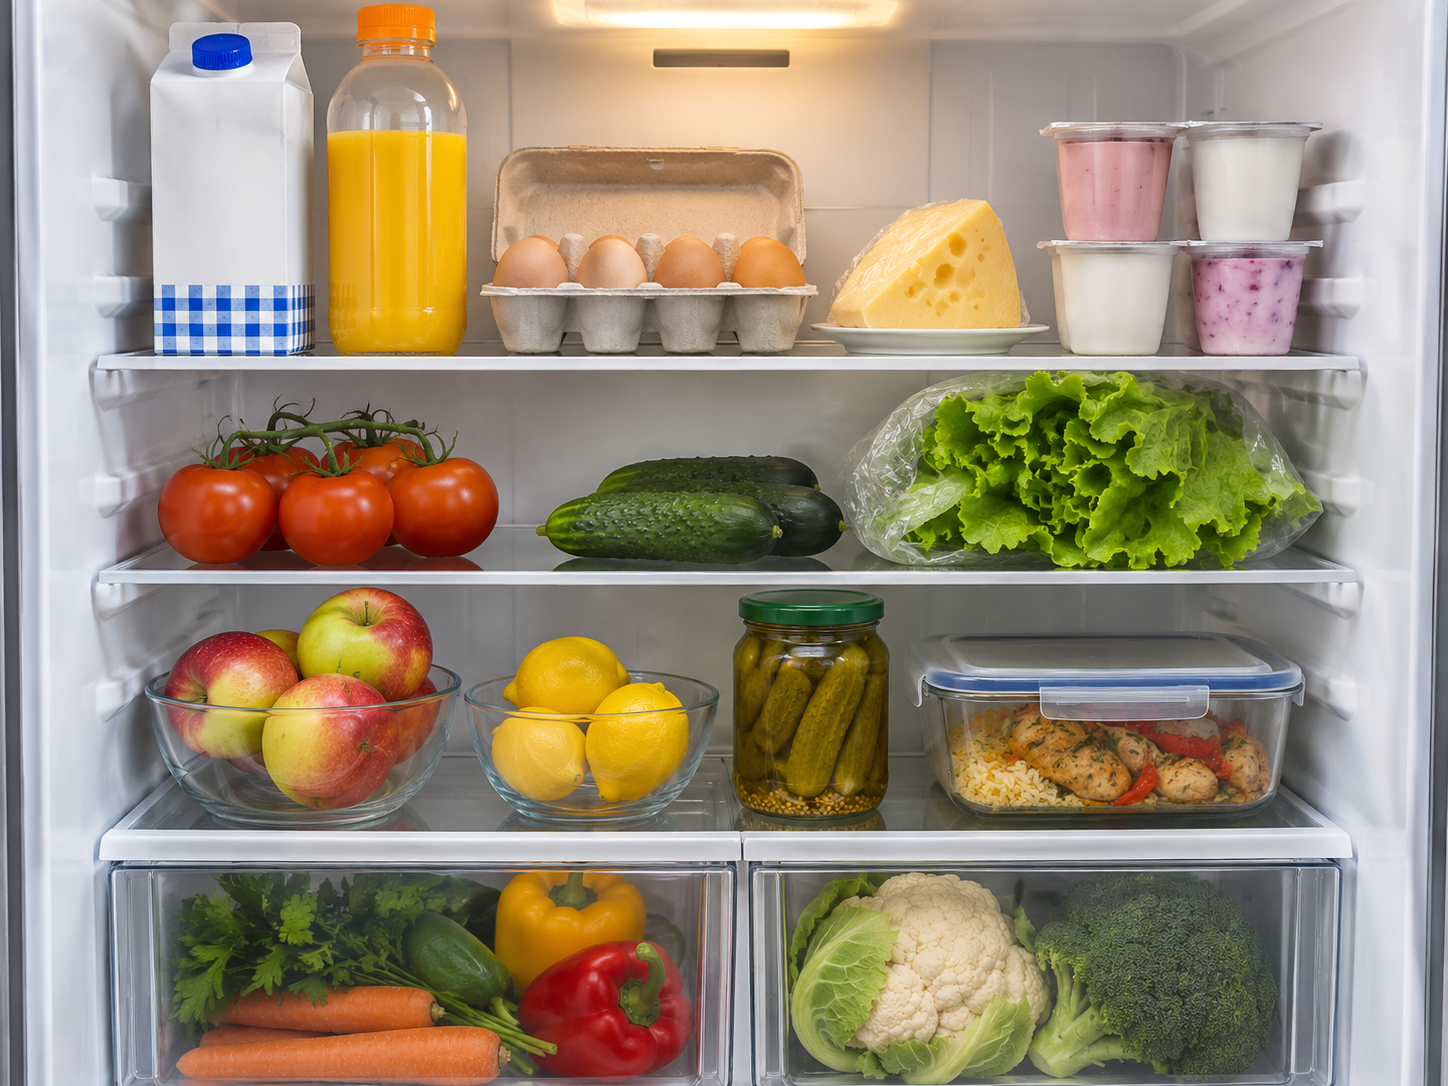

2. Входной голосовой вопрос:


3. Транскрипция Whisper: Посмотри на фотографию холодильника, какие продукты ты видишь, что можно приготовить из них на ужин, предложить два простых блюда.
4. Текстовый ответ Qwen: На фото видны овощи (томаты, огурцы, перец, морковь, капуста, брокколи), зелень, яблоки, лимоны, яйца, сыр, молоко, йогурты, консервированные огурцы и готовое блюдо с курицей и рисом. 

Можно приготовить: 
1) Салат из свежих овощей с яйцом and сыром; 
2)二次加热 existing chicken and rice dish for a quick dinner.
5. Сгенерированное аудио Silero:


6. Задержки по этапам, секунды: {'ASR': 2.247064032002527, 'VLM': 1.5369309350062395, 'TTS': 1.4152878290042281, 'TOTAL': 5.1993444740001}


In [2]:
from IPython.display import display, Audio, Image, Markdown

# Берём последнюю успешную папку базового сценария.
folders = sorted(RESULT_DIR.glob("fridge_baseline_*/result.json"))
if not folders:
    raise FileNotFoundError("Нет данных fridge_baseline. Сначала запусти evaluate.py")
record_path = folders[-1]
example = json.loads(record_path.read_text(encoding="utf-8"))
example_dir = record_path.parent
image_path = example_dir / example["inputs"]["image"]
input_audio_path = example_dir / example["inputs"]["audio"]
answer_audio_path = example_dir / example["output_audio"]

for path in (image_path, input_audio_path, answer_audio_path):
    if not path.is_file():
        raise FileNotFoundError(path)

print("1. Входное изображение:")
display(Image(filename=str(image_path), width=500))
print("2. Входной голосовой вопрос:")
display(Audio(filename=str(input_audio_path)))
print("3. Транскрипция Whisper:", example["transcription"])
print("4. Текстовый ответ Qwen:", example["answer"])
print("5. Сгенерированное аудио Silero:")
display(Audio(filename=str(answer_audio_path)))
print("6. Задержки по этапам, секунды:", example["latency_seconds"])

### Скриншоты работающего Gradio

Все три скриншота сделаны после обработки запроса и показывают входное изображение, аудиовопрос, транскрипцию, ответ, аудиоплеер и время. Они лежат в `screenshots/` рядом с кодом проекта.

**Базовый сценарий: холодильник**

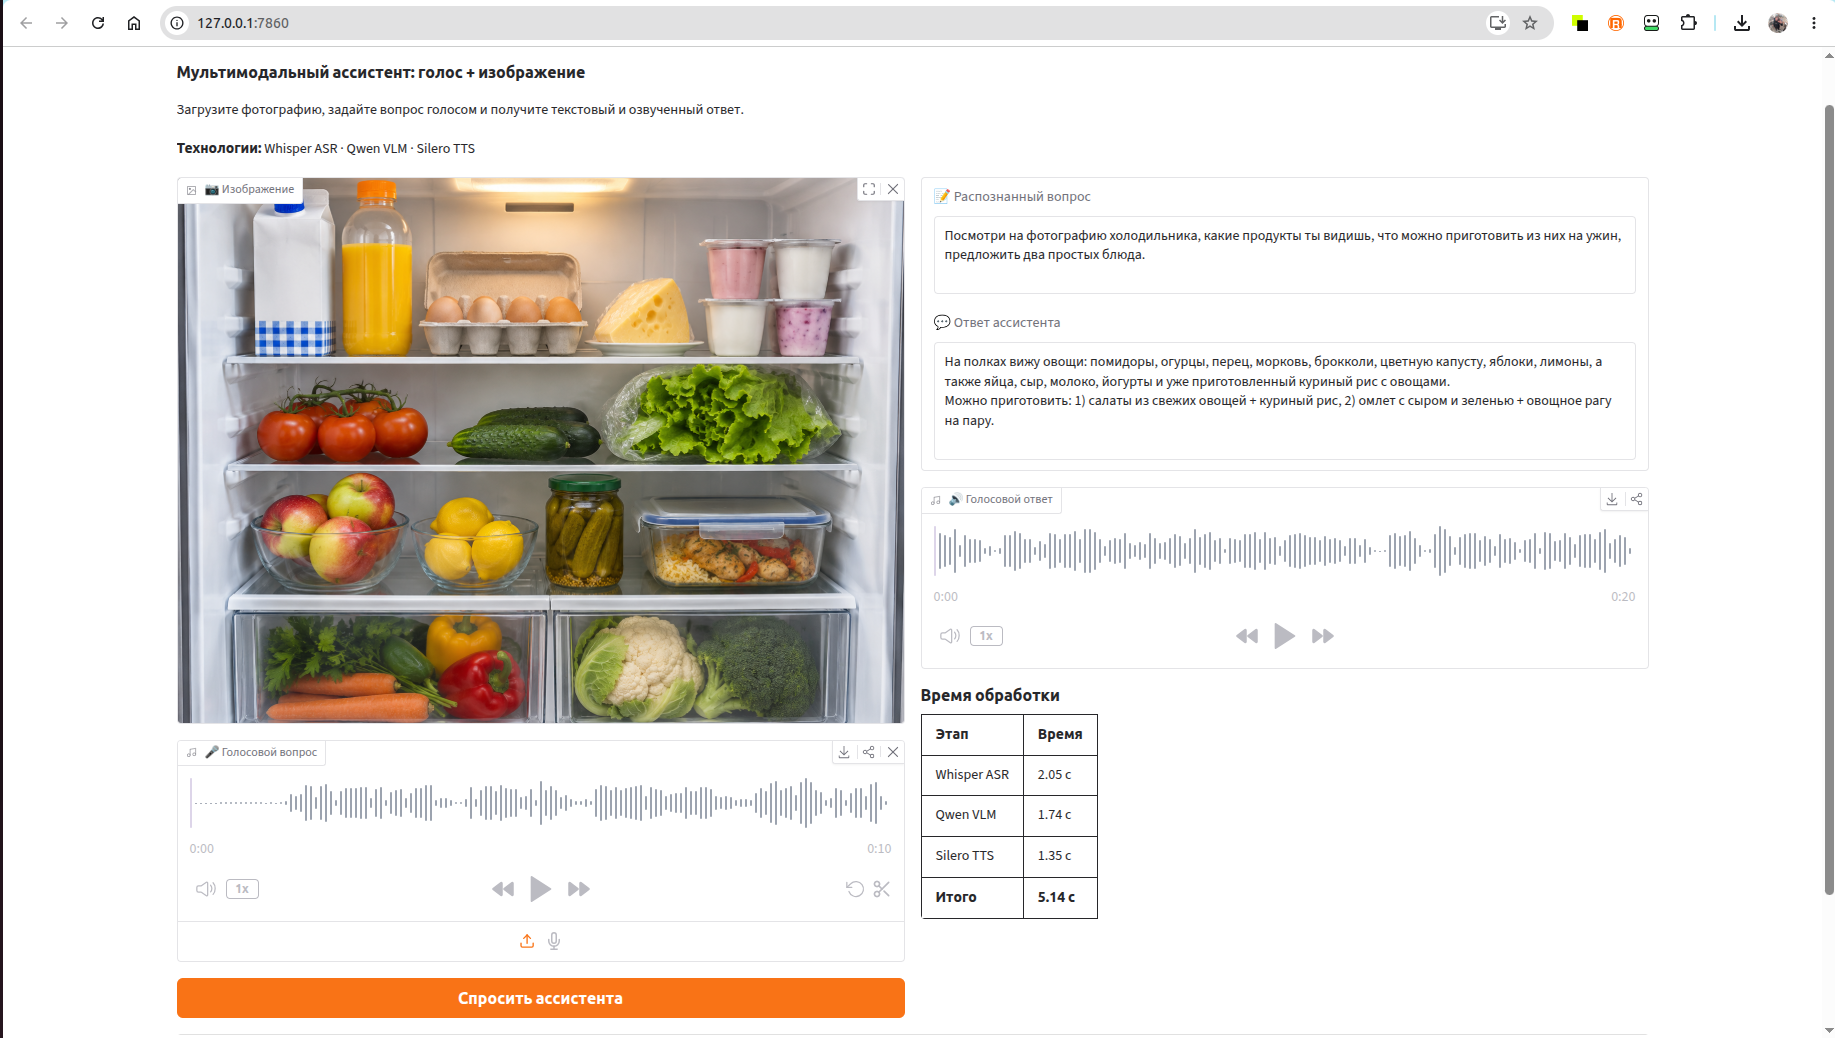

**Точное чтение этикетки**

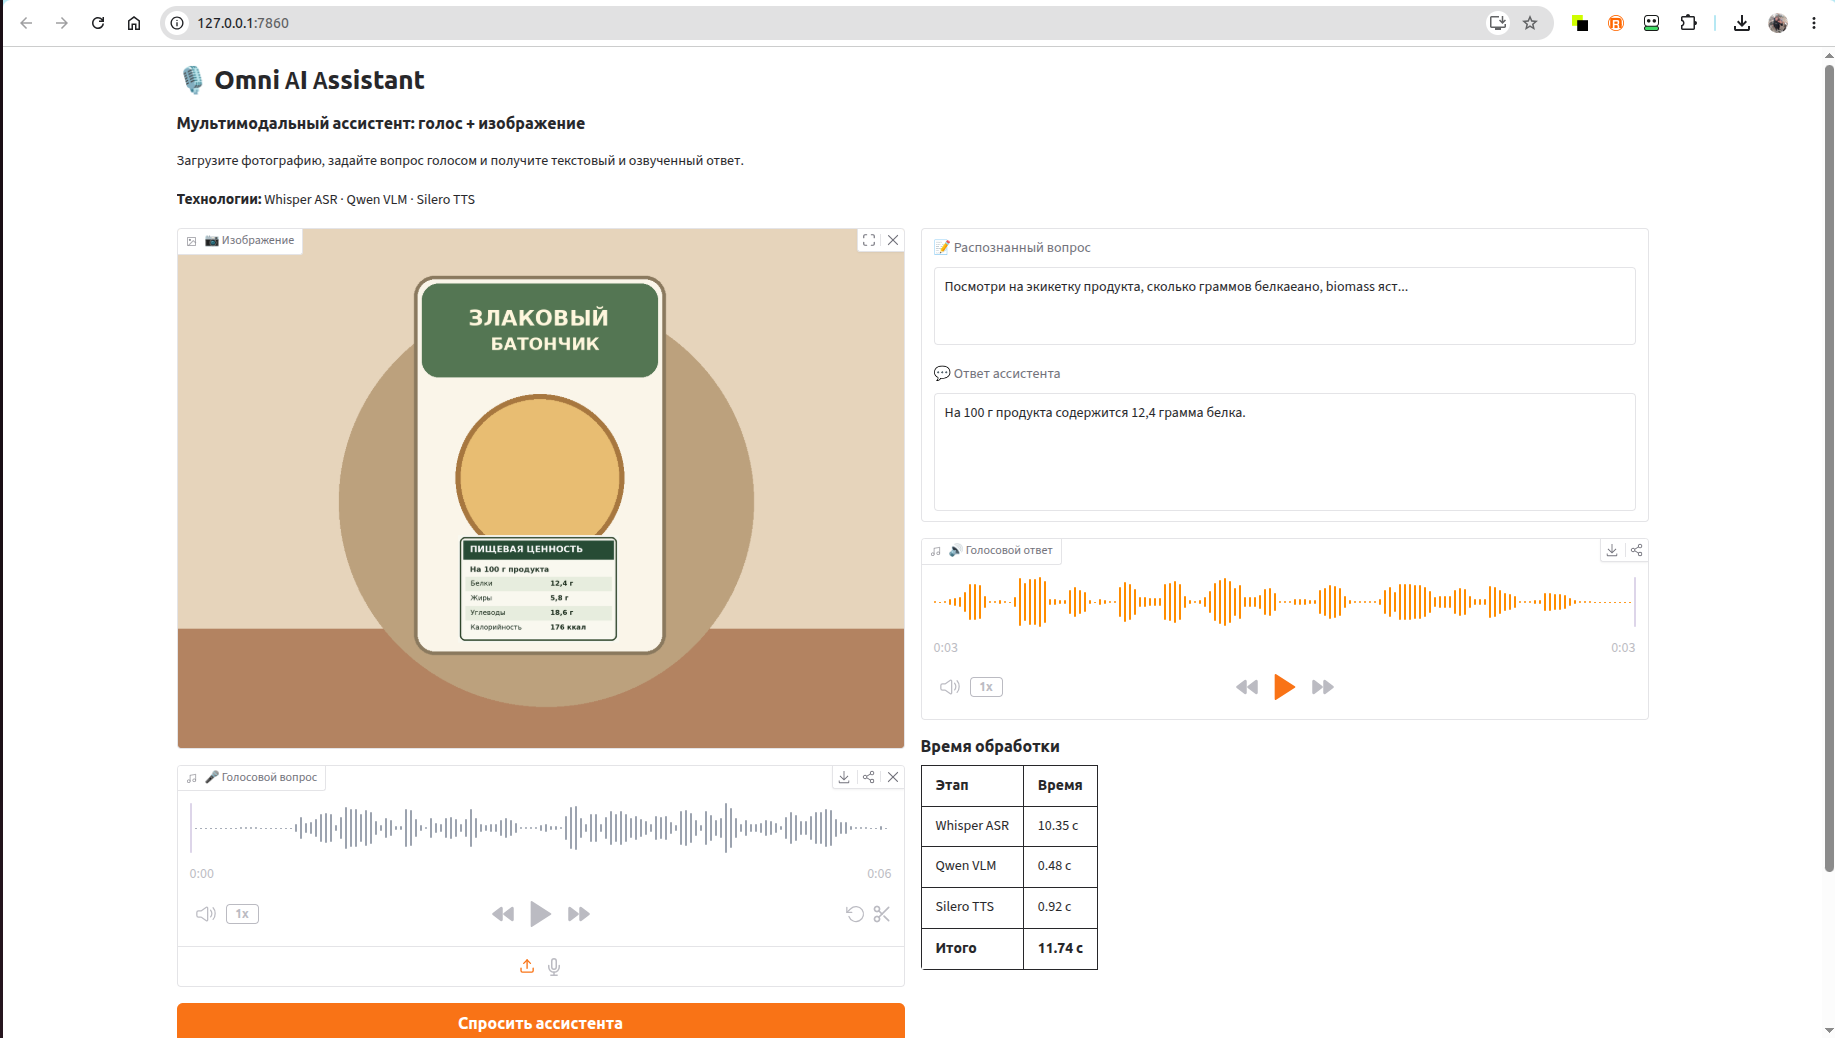

**Проверка отсутствующих объектов**

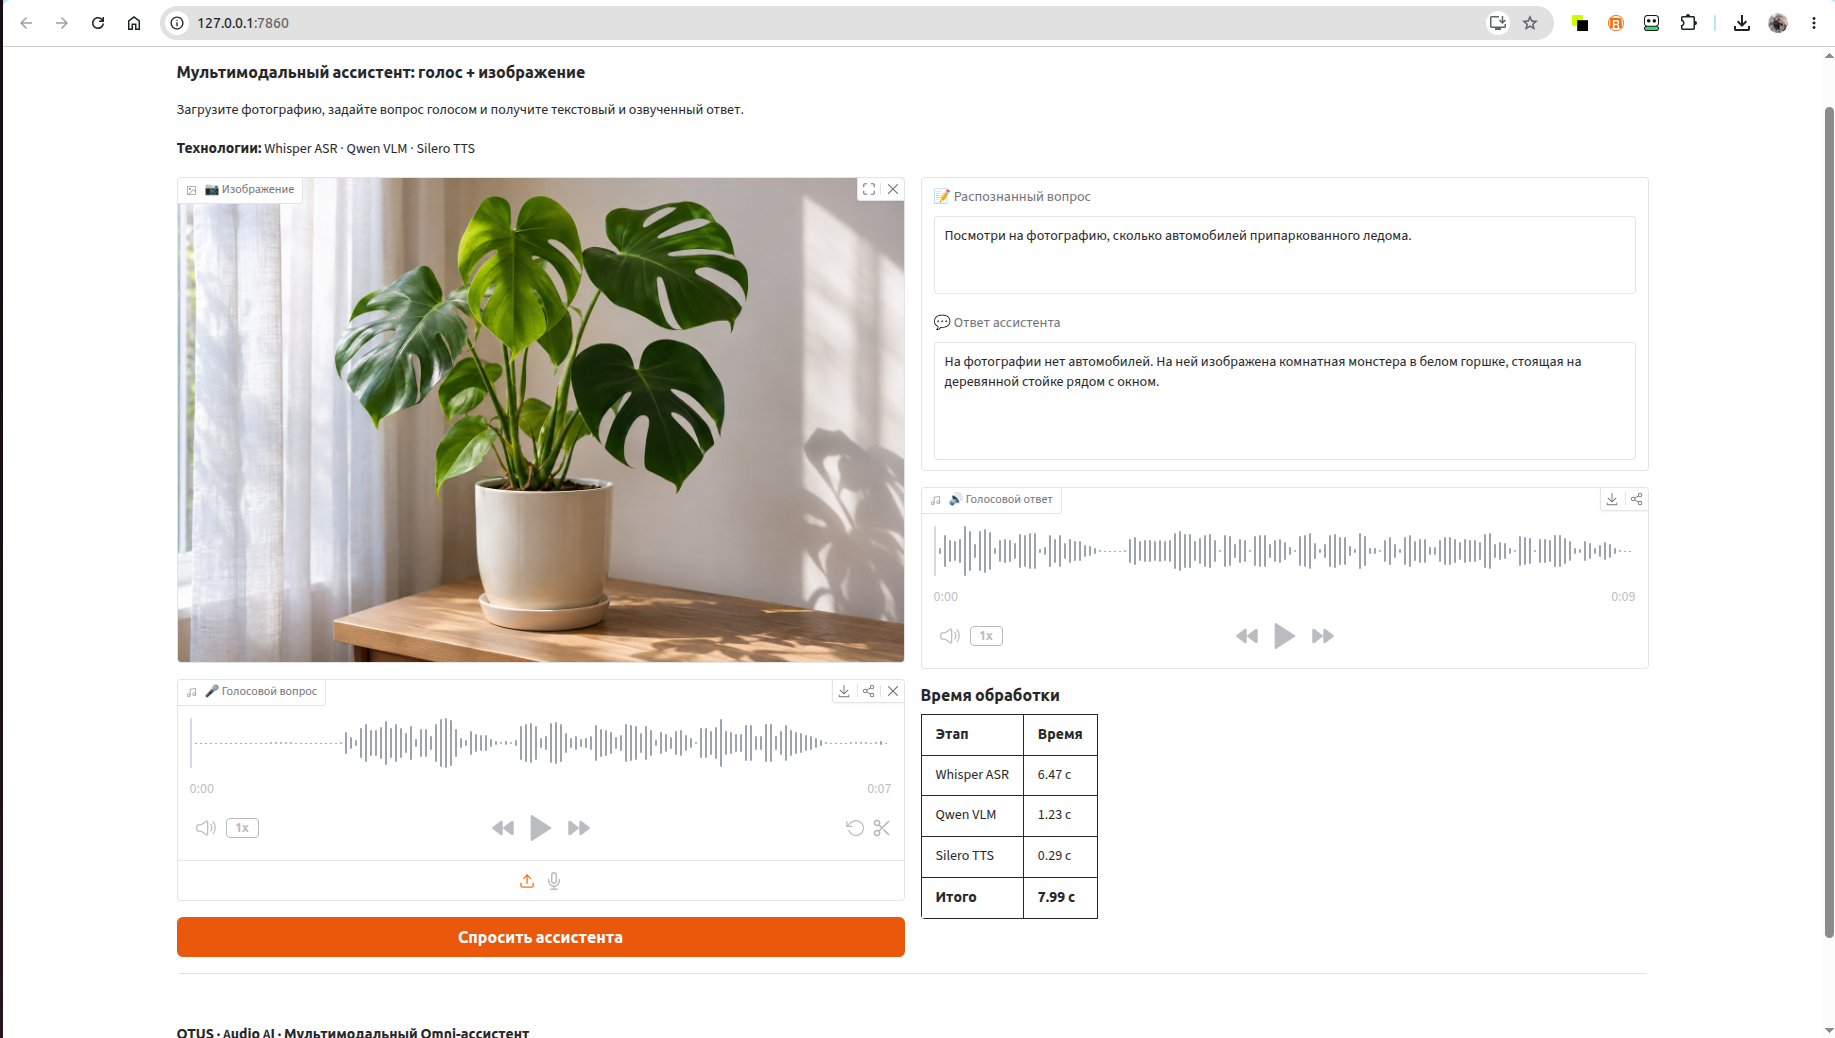

In [3]:
for title, filename in [
    ("Базовый сценарий: холодильник", "screenshot-fridge.png"),
    ("Точное чтение этикетки", "screenshot-nutrition.png"),
    ("Проверка отсутствующих объектов", "screenshot-plant.png"),
]:
    path = ROOT / "screenshots" / filename
    if path.exists():
        display(Markdown(f"**{title}**"))
        display(Image(filename=str(path), width=850))
    else:
        print("Скриншот отсутствует:", path)

### Необязательный новый прогон (платный API-запрос)

По умолчанию **выключен**: повторный запуск загрузит модели Whisper/Silero и отправит изображение в Yandex AI Studio. Для воспроизведения сохранённых результатов он не нужен. Перед включением настрой `.env`, зависимости и локальный кэш Silero.

In [4]:
RUN_NEW_EXPERIMENT = False  # Поменяй на True, только если нужен новый вызов API

if RUN_NEW_EXPERIMENT:
    from pipeline import OmniAssistant
    assistant = OmniAssistant()
    fresh = assistant.run_omni_assistant(
        image=ROOT / "samples/images/fridge.png",
        audio_query=ROOT / "samples/audio/fridge_question.ogg",
    )
    print("Распознанный вопрос:", fresh["question"])
    print("Ответ:", fresh["answer"])
    print("Задержки:", fresh["timings"])
    display(Audio(filename=fresh["audio_path"]))
else:
    print("Повторный API-вызов отключён. Выше показан сохранённый результат.")

Повторный API-вызов отключён. Выше показан сохранённый результат.


In [5]:
rows = []
for file in sorted(RESULT_DIR.glob("*/result.json")):
    record = json.loads(file.read_text(encoding="utf-8"))
    latency = record.get("latency_seconds", {})
    rows.append({
        "experiment": record.get("experiment", file.parent.name),
        "timestamp": record.get("timestamp_utc", ""),
        "transcription": record.get("transcription", ""),
        "answer": record.get("answer", ""),
        "ASR": latency.get("ASR"),
        "VLM": latency.get("VLM"),
        "TTS": latency.get("TTS"),
        "TOTAL": latency.get("TOTAL"),
        "source": str(file.relative_to(ROOT)),
    })
all_runs = pd.DataFrame(rows)
if all_runs.empty:
    raise RuntimeError("Не найдено ни одного result.json. Сначала перенеси сохранённые результаты экспериментов.")
# Для каждого названия сценария показываем наиболее поздний запуск.
latest = (all_runs.sort_values("timestamp")
                  .drop_duplicates("experiment", keep="last")
                  .sort_values("experiment")
                  .reset_index(drop=True))
display(latest[["experiment", "ASR", "VLM", "TTS", "TOTAL"]].round(2))


,experiment,ASR,VLM,TTS,TOTAL
0,fridge_baseline,2.25,1.54,1.42,5.20
1,fridge_noisy_15db,2.07,1.41,1.01,4.49
2,fridge_noisy_5db,11.16,1.19,0.77,13.12
3,nutrition_full,10.90,0.61,0.83,12.35
4,nutrition_zoom,11.08,0.52,0.80,12.39
5,plant_hallucination,10.35,1.30,0.90,12.55


## 3. Сравнение задержек

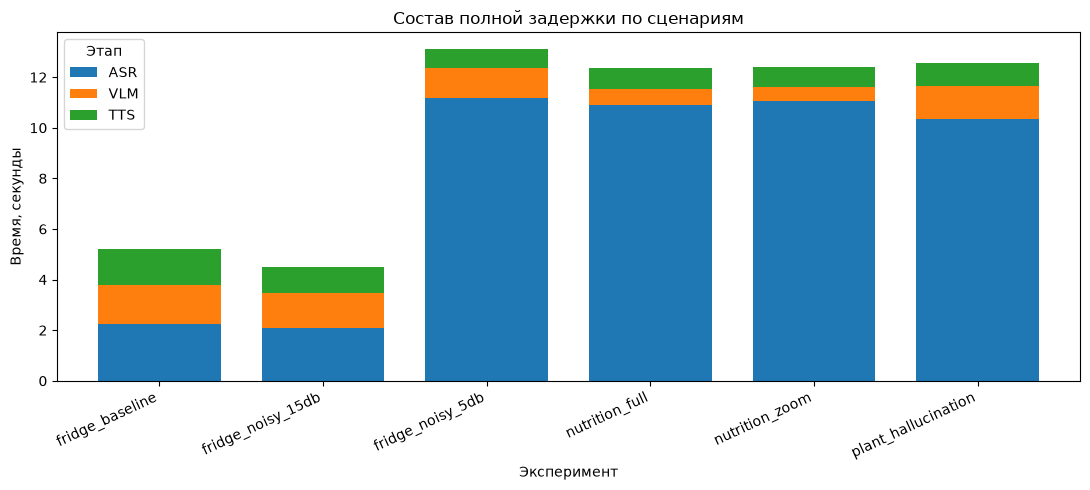

In [6]:
selected_names = [
    "fridge_baseline", "fridge_noisy_15db", "fridge_noisy_5db",
    "nutrition_full", "nutrition_zoom", "plant_hallucination",
]
selected = latest[latest.experiment.isin(selected_names)].copy()
assert not selected.empty, "Нет записанных запусков для основных сценариев"
ax = selected.set_index("experiment")[["ASR", "VLM", "TTS"]].plot(
    kind="bar", stacked=True, figsize=(11, 5), width=.75)
ax.set_title("Состав полной задержки по сценариям")
ax.set_xlabel("Эксперимент")
ax.set_ylabel("Время, секунды")
ax.legend(title="Этап")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


**Интерпретация.** При чтении этикетки и ошибочном голосовом запросе наблюдалась особенно большая задержка ASR. Увеличение этикетки в одном прогоне уменьшило VLM latency с 0,81 до 0,47 с, но не доказано, что эффект устойчив или вызван только масштабом изображения.

## 4. Шум и распознавание речи

In [7]:
noise_file = RESULT_DIR / "asr_noise/report.json"
if noise_file.exists():
    report = json.loads(noise_file.read_text(encoding="utf-8"))
    noise_df = pd.DataFrame(report["results"])
    display(noise_df[["scenario", "transcription", "latency_seconds", "wer"]])
    if noise_df["wer"].notna().any():
        print("WER рассчитан по reference_text в отчёте; проверь, что эталон размечен вручную.")
    else:
        print("WER не рассчитан: в отчёте нет подтверждённой эталонной транскрипции.")
else:
    print("Нет файла", noise_file)


,scenario,transcription,latency_seconds,wer
0,original,"Посмотри на фотографию холодильника, какие про...",1.069,None
1,snr_15db,"Посмотри на подогряти у холодильника, такие пр...",0.921,None
2,snr_5db,"Отмотена подогрячая стройби, на какие продукци...",1.112,None


WER не рассчитан: в отчёте нет подтверждённой эталонной транскрипции.


**Наблюдение:** в отдельном локальном ASR-тесте при 15 dB часть ключевых слов сохранялась, при 5 dB распознавание было сильно искажено. В полном пайплайне при 5 dB Whisper вернула ещё более короткий бессмысленный текст. Причины расхождения между прогонами не установлены.

## 5. Ответы модели: аудит качества

In [8]:
quality = latest[latest.experiment.isin(selected_names)][["experiment", "transcription", "answer"]]
for _, r in quality.iterrows():
    print("\n" + "=" * 70)
    print("ЭКСПЕРИМЕНТ:", r.experiment)
    print("ASR:", r.transcription)
    print("VLM:", r.answer)



ЭКСПЕРИМЕНТ: fridge_baseline
ASR: Посмотри на фотографию холодильника, какие продукты ты видишь, что можно приготовить из них на ужин, предложить два простых блюда.
VLM: На фото видны овощи (томаты, огурцы, перец, морковь, капуста, брокколи), зелень, яблоки, лимоны, яйца, сыр, молоко, йогурты, консервированные огурцы и готовое блюдо с курицей и рисом. 

Можно приготовить: 
1) Салат из свежих овощей с яйцом and сыром; 
2)二次加热 existing chicken and rice dish for a quick dinner.

ЭКСПЕРИМЕНТ: fridge_noisy_15db
ASR: Посмотри на подогряти у холодильника, такие продукты видишь, что он приготовить и вид на ужин, предложить два простых блюда.
VLM: Горячую котлету с рисом лучше просто разогреть — это готовое блюдо. Для ужина предложу салат из овощей (помидоры, огурцы, капуста, перец) и омлет из яиц с молоком — быстро и питательно.

ЭКСПЕРИМЕНТ: fridge_noisy_5db
ASR: подşу над
VLM: Топ-шкафы — это специальные поисковые системы, предлагающие информацию по будущему.

ЭКСПЕРИМЕНТ: nutrition_full
AS

### Ручная оценка по известным эталонам

| Сценарий | Наблюдение | Оценка |
|---|---|---|
| Холодильник, исходная запись | Названы продукты и 2 блюда; встречались неподтверждённые детали | Частично верно |
| Холодильник, 15 dB | Намерение «предложить ужин» сохранено, несмотря на ошибки ASR | Частично верно |
| Холодильник, 5 dB | Модель сообщила о непонятном запросе; не восстановила изначальное намерение | Безопасная неопределённость, но ответ избыточен |
| Этикетка, полное изображение | Белок 12,4 г/100 г; добавлено замечание о бессмысленных словах ASR | Верно по факту, избыточно |
| Этикетка, увеличенный фрагмент | Белок 12,4 г/100 г | Верно |
| Растение / несуществующие автомобили | Отсутствие автомобилей признано, описано растение | Верно |

Эта таблица — **ручная качественная разметка** по одному запуску, а не автоматическая метрика точности модели.


## 6. Дополнительный анализ: стоимость и токены

В отдельных диагностических выводах API сохранялось количество входных и выходных токенов, но текущий `result.json` не обязательно содержит эти данные. Поэтому нельзя строить достоверный агрегированный график стоимости на основе отсутствующих полей. Для будущих тестов рекомендуется сохранять `usage` в экспериментальный JSON и отдельно считать цену по актуальному тарифу поставщика.

## 7. Выводы и рекомендации

1. **Мультимодальность частично компенсирует ошибки ASR.** При 15 dB Qwen поняла задачу в присутствии визуального контекста, но одно испытание не доказывает, что именно изображение было решающим: нужен контрольный запрос без фото.
2. **При сильном шуме входная речь становится неразборчивой.** Ассистенту нужна политика уточняющих вопросов вместо угадывания намерения.
3. **VLM справилась с чтением цифр** на двух вариантах этикетки (12,4 г белка). На увеличенном фрагменте ответ был короче, а задержка VLM ниже в данном прогоне.
4. **Тест отсутствующего объекта пройден:** модель не назвала вымышленное количество автомобилей.
5. **Узкое место — ASR и голосовой UX:** отдельные записи обрабатывались Whisper 8–11 секунд, хотя VLM отвечала менее чем за 2 секунды.
6. **Ограничения работы:** нет статистически устойчивых замеров, нет подтверждённого WER и нет локальной 4-bit Qwen3-VL-4B. Отдельно стоит проверить пользовательское разрешение на облачную VLM в рамках задания.

### Возможные доработки после сдачи

- Добавить VAD, предобработку/подавление шума и диагностику длительных ASR-декодирований.
- Ввести в промпт инструкцию уточнять неразборчивые вопросы и не перечислять лишние детали.
- Сделать 5–10 повторов сценариев, фиксировать конфигурацию декодирования и распределение задержек.
- Провести контрольный A/B-тест одинакового повреждённого текста с изображением и без него.
